In [33]:
from google.colab import files
uploaded = files.upload()

Saving weather_risk_factors.csv to weather_risk_factors (1).csv
Saving vehicle_sensor_profiles.csv to vehicle_sensor_profiles (1).csv
Saving road_environment_factors.csv to road_environment_factors (1).csv
Saving intervention_events.csv to intervention_events (1).csv
Saving autonomous_vehicle_journeys.csv to autonomous_vehicle_journeys (1).csv


In [34]:
import pandas as pd
pd.set_option("display.max_columns", None)
autonomous_vehicle_journeys = pd.read_csv("autonomous_vehicle_journeys.csv")
weather_risk_factors = pd.read_csv("weather_risk_factors.csv")
vehicle_sensor_profiles = pd.read_csv("vehicle_sensor_profiles.csv")
road_environment_factors = pd.read_csv("road_environment_factors.csv")
intervention_events = pd.read_csv("intervention_events.csv")

intervention_events.head()

,event_id,journey_id,event_type,event_reason,severity,response_action,outcome
0,EVT-0001,AVJ-00003,Emergency stop,Emergency stop,Medium,Safe stop and system check,Journey completed
1,EVT-0002,AVJ-00007,Human intervention,Complex traffic,Low,Manual control requested,Journey completed
2,EVT-0003,AVJ-00008,Safety incident,Safety incident,High,Journey terminated,Journey not completed
3,EVT-0004,AVJ-00017,Human intervention,Unexpected obstacle,Low,Remote operator review,Journey completed
4,EVT-0005,AVJ-00019,Emergency stop,Emergency stop,Medium,Safe stop and system check,Journey not completed


In [35]:
intervention_events['outcome'].unique()

array(['Journey completed', 'Journey not completed'], dtype=object)

In [36]:
datasets ={'journeys': autonomous_vehicle_journeys,
           'sensors': vehicle_sensor_profiles,
           'road': road_environment_factors,
           'weather': weather_risk_factors,
           'interventions': intervention_events}

In [37]:
for name, df in datasets.items():
  print(f"---\n {name}---")
  print(df.dtypes)
  print(df.isnull().sum())
  df.info()
  print(df.shape)

---
 journeys---
journey_id                object
journey_date              object
time_of_day               object
city                      object
road_segment_id           object
vehicle_profile_id        object
weather_code              object
road_type                 object
distance_km              float64
traffic_level             object
road_surface              object
visibility_km            float64
planned_time_min           int64
actual_time_min            int64
delay_min                  int64
sensor_confidence_pct    float64
sensor_alert_count         int64
unexpected_obstacle       object
human_intervention        object
emergency_stop            object
safety_incident           object
journey_completed         object
passenger_rating_1to5      int64
problem_occurred          object
risk_level                object
dtype: object
journey_id               0
journey_date             0
time_of_day              0
city                     0
road_segment_id          0
vehicle_p

note: no missing data and no wierd data types

In [38]:
#merge tables
merged_table1 = pd.merge(autonomous_vehicle_journeys, vehicle_sensor_profiles, on='vehicle_profile_id', how='left')
merged_table2 = pd.merge(merged_table1, weather_risk_factors, on='weather_code', how='left')
merged_table3 = pd.merge(merged_table2, road_environment_factors, on='road_segment_id', how='left')

In [39]:
final_merged_table = pd.merge(merged_table3, intervention_events, on = "journey_id", how = "left")
final_merged_table.head()

,journey_id,journey_date,time_of_day,city_x,road_segment_id,vehicle_profile_id,weather_code,road_type_x,distance_km,traffic_level,road_surface,visibility_km,planned_time_min,actual_time_min,delay_min,sensor_confidence_pct,sensor_alert_count,unexpected_obstacle,human_intervention,emergency_stop,safety_incident,journey_completed,passenger_rating_1to5,problem_occurred,risk_level,vehicle_model,software_version,sensor_suite,lidar_units,radar_units,camera_units,vehicle_age_months,nominal_sensor_confidence_pct,weather,risk_multiplier,visibility_factor,sensor_confidence_adjustment,city_y,road_type_y,speed_limit_mph,junction_complexity,road_markings,street_lighting,digital_infrastructure,event_id,event_type,event_reason,severity,response_action,outcome
0,AVJ-00001,2026-04-12,Morning peak,Newcastle,SEG-018,VP-08,W07,B road,39.2,High,Dry,9.6,71,78,7,87.6,2,No,No,No,No,Yes,4,No,Low,Vector One,5.0,Enhanced,3,7,10,10,90,Low sun,1.30,0.70,-6,Newcastle,B road,50,Low,Good,Standard,Standard,NaN,NaN,NaN,NaN,NaN,NaN
1,AVJ-00002,2026-06-01,Night,Cardiff,SEG-009,VP-04,W01,Urban street,49.0,Moderate,Dry,4.2,148,150,2,93.5,1,No,No,No,No,Yes,5,No,Low,Vector Plus,5.0,Enhanced,3,7,10,21,90,Clear,1.00,1.00,2,Cardiff,Urban street,30,High,Good,Good,Standard,NaN,NaN,NaN,NaN,NaN,NaN
2,AVJ-00003,2026-02-18,Daytime,Cardiff,SEG-027,VP-08,W05,A road,11.3,Moderate,Snow-covered,4.0,17,36,19,65.9,5,No,Yes,Yes,No,Yes,2,Yes,High,Vector One,5.0,Enhanced,3,7,10,10,90,Snow,1.85,0.45,-15,Cardiff,A road,60,Low,Good,Standard,Standard,EVT-0001,Emergency stop,Emergency stop,Medium,Safe stop and system check,Journey completed
3,AVJ-00004,2026-06-23,Daytime,Cardiff,SEG-021,VP-08,W02,Motorway,15.3,Moderate,Wet,10.3,20,21,1,82.0,2,No,No,No,No,Yes,4,No,Low,Vector One,5.0,Enhanced,3,7,10,10,90,Light rain,1.15,0.82,-3,Cardiff,Motorway,70,Medium,Good,Limited,Standard,NaN,NaN,NaN,NaN,NaN,NaN
4,AVJ-00005,2026-05-08,Daytime,Bristol,SEG-026,VP-04,W02,Motorway,25.1,Moderate,Wet,3.9,32,35,3,88.5,1,No,No,No,No,Yes,5,No,Low,Vector Plus,5.0,Enhanced,3,7,10,21,90,Light rain,1.15,0.82,-3,Bristol,Motorway,70,Low,Good,Standard,Standard,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
final_merged_table.isnull().sum()

,0
journey_id,0
journey_date,0
time_of_day,0
city_x,0
road_segment_id,0
vehicle_profile_id,0
weather_code,0
road_type_x,0
distance_km,0
traffic_level,0


In [41]:
intervention_events['journey_id'].nunique()

377

In [42]:
final_merged_table['event_id'].isna().sum()

np.int64(2123)

Investigate the Overall problem rate

In [43]:
final_merged_table['problem_flag'] = (final_merged_table['problem_occurred']=="Yes").astype(int)

In [44]:
final_merged_table['problem_flag'].value_counts(dropna=False)

,count
problem_flag,
0,1999
1,501


In [45]:
overall_problem_rate = final_merged_table['problem_flag'].mean() * 100

print("Overall problem rate:", round(overall_problem_rate, 2), "%")

Overall problem rate: 20.04 %


In [46]:
total_journeys = len(final_merged_table)

problem_journeys = final_merged_table['problem_flag'].sum()

no_problem_journeys = (final_merged_table['problem_flag'] == 0).sum()

missing_outcomes = final_merged_table['problem_flag'].isna().sum()

print("Total journeys:", total_journeys)
print("Journeys with problems:", problem_journeys)
print("Journeys without problems:", no_problem_journeys)
print("Missing outcomes:", missing_outcomes)

Total journeys: 2500
Journeys with problems: 501
Journeys without problems: 1999
Missing outcomes: 0


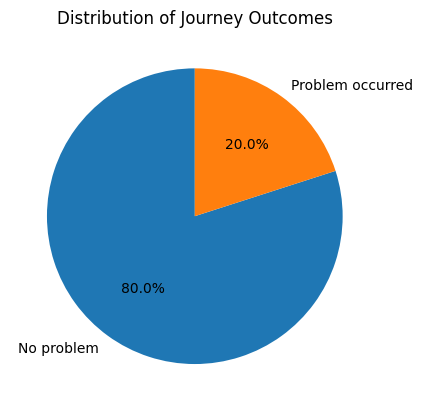

In [47]:
import matplotlib.pyplot as plt

plt.pie(
    final_merged_table['problem_flag'].value_counts().sort_index(),
    labels=['No problem', 'Problem occurred'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Journey Outcomes')
plt.show()

Investigating weather and visibility

Which weather category has the highest problem rate?

In [48]:
weather_analysis = (final_merged_table.groupby('weather')['problem_flag'].agg(['count', 'sum', 'mean']))

weather_analysis['problem_rate_pct'] = (weather_analysis['mean'] * 100)

print(weather_analysis.sort_values('problem_rate_pct',ascending=False).round(2))

             count  sum  mean  problem_rate_pct
weather                                        
Snow            86   41  0.48             47.67
Fog            160   52  0.32             32.50
Heavy rain     203   56  0.28             27.59
Low sun        141   37  0.26             26.24
Heat alert      59   13  0.22             22.03
Light rain     475   85  0.18             17.89
Strong wind    163   27  0.17             16.56
Clear         1213  190  0.16             15.66


Snow has the highest problem rate with 47.67%

Do journeys with lower visibility have higher problem rates?

In [49]:
visibility = final_merged_table.groupby('visibility_factor')['problem_flag'].mean().mul(100).sort_values(ascending=False)
visibility

,problem_flag
visibility_factor,
0.45,47.674419
0.25,32.500000
0.55,27.586207
0.70,26.241135
0.95,22.033898
0.82,17.894737
0.90,16.564417
1.00,15.663644


In [50]:
visibility_km = final_merged_table.groupby('visibility_km')['problem_flag'].mean().mul(100).sort_values(ascending=False)
visibility_km.head(50)

,problem_flag
visibility_km,
0.9,100.000000
1.6,75.000000
1.4,66.666667
14.2,55.555556
18.2,50.000000
1.7,50.000000
5.0,46.153846
8.1,41.176471
12.6,40.000000


Does the road surface condition make a difference?

In [51]:
road_surface = final_merged_table.groupby('road_surface')['problem_flag'].mean(). mul(100).sort_values(ascending=False)
road_surface

,problem_flag
road_surface,
Snow-covered,47.674419
Wet,20.796460
Dry,18.583535
Uneven,14.285714


In [52]:
weather_surface_analysis = (final_merged_table.groupby(['weather', 'road_surface'])['problem_flag'].agg(['count', 'sum', 'mean']))

weather_surface_analysis['problem_rate_pct'] = (weather_surface_analysis['mean'] * 100)

print(weather_surface_analysis.sort_values('problem_rate_pct', ascending=False).round(2))

                          count  sum  mean  problem_rate_pct
weather     road_surface                                    
Snow        Snow-covered     86   41  0.48             47.67
Fog         Dry             151   50  0.33             33.11
Heavy rain  Wet             203   56  0.28             27.59
Low sun     Dry             135   36  0.27             26.67
Heat alert  Dry              57   13  0.23             22.81
Fog         Uneven            9    2  0.22             22.22
Light rain  Wet             475   85  0.18             17.89
Strong wind Uneven            6    1  0.17             16.67
Low sun     Uneven            6    1  0.17             16.67
Strong wind Dry             157   26  0.17             16.56
Clear       Dry            1152  182  0.16             15.80
            Uneven           61    8  0.13             13.11
Heat alert  Uneven            2    0  0.00              0.00


In [53]:
weather_surface_analysis = (final_merged_table.groupby(['weather', 'visibility_factor'])['problem_flag'].agg(['count', 'sum', 'mean']))

weather_surface_analysis['problem_rate_pct'] = (weather_surface_analysis['mean'] * 100)

print(weather_surface_analysis.sort_values('problem_rate_pct', ascending=False).round(2))

                               count  sum  mean  problem_rate_pct
weather     visibility_factor                                    
Snow        0.45                  86   41  0.48             47.67
Fog         0.25                 160   52  0.32             32.50
Heavy rain  0.55                 203   56  0.28             27.59
Low sun     0.70                 141   37  0.26             26.24
Heat alert  0.95                  59   13  0.22             22.03
Light rain  0.82                 475   85  0.18             17.89
Strong wind 0.90                 163   27  0.17             16.56
Clear       1.00                1213  190  0.16             15.66


In [54]:
pd.set_option('display.max_rows', None)
weather_surface_analysis = (final_merged_table.groupby(['weather', 'visibility_km'])['problem_flag'].agg(['count', 'sum', 'mean']))

weather_surface_analysis['problem_rate_pct'] = (weather_surface_analysis['mean'] * 100)

print(weather_surface_analysis.sort_values('problem_rate_pct', ascending=False).round(2))

                           count  sum  mean  problem_rate_pct
weather     visibility_km                                    
Strong wind 11.2               1    1  1.00            100.00
            8.6                2    2  1.00            100.00
            13.2               1    1  1.00            100.00
            13.4               1    1  1.00            100.00
            14.8               1    1  1.00            100.00
            12.2               1    1  1.00            100.00
            8.3                1    1  1.00            100.00
Snow        8.4                2    2  1.00            100.00
            5.7                1    1  1.00            100.00
            6.6                1    1  1.00            100.00
            6.4                1    1  1.00            100.00
Strong wind 4.4                1    1  1.00            100.00
            8.0                1    1  1.00            100.00
            10.7               1    1  1.00            100.00
Snow    

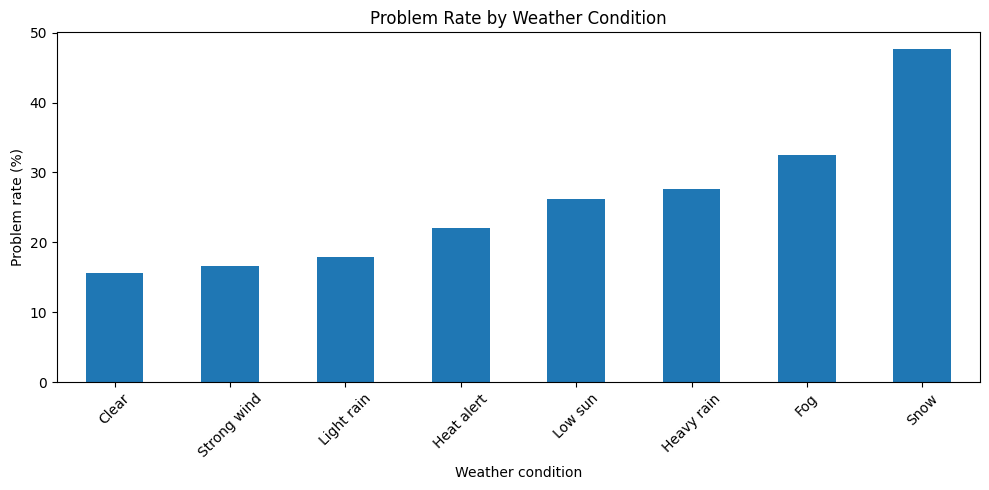

In [55]:
weather_analysis['problem_rate_pct'].sort_values().plot(kind='bar', figsize=(10,5))
plt.xlabel('Weather condition')
plt.ylabel('Problem rate (%)')
plt.title('Problem Rate by Weather Condition')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The combined analysis of weather and road surface conditions identified snow and snow-covered roads as having the highest observed problem rate, at 47.67%, across 86 journeys. This was consistent with the original weather analysis, where snow also recorded 47.67% across 86 journeys.

Fog and dry roads recorded a problem rate of 33.11% across 151 journeys, while heavy rain and wet roads recorded 27.59% across 203 journeys.

An important observation was that all 86 snowy journeys were associated with snow-covered road surfaces. This means the individual relationship between snowy weather and snow-covered road conditions cannot be separated using the available observations.

Clear weather and dry roads accounted for the largest group, with 1,152 journeys and a problem rate of 15.80%. This demonstrates that recorded problems were not restricted to adverse weather conditions.

Some combinations contained very few observations. For example, heat alert and uneven roads contained only two journeys. Their 0% problem rate should therefore not be interpreted as evidence of safety.

Overall, environmental conditions appear to be associated with differences in journey problem rates. Further investigation of sensor performance, road characteristics and other factors is required before drawing conclusions about the causes of these problems.

Investigating sensor reliability

Do journeys with lower sensor confidence have higher problem rates?

In [56]:
print(final_merged_table['sensor_confidence_pct'].describe())

count    2500.000000
mean       85.878600
std         7.340491
min        57.600000
25%        81.900000
50%        86.900000
75%        91.200000
max        99.000000
Name: sensor_confidence_pct, dtype: float64


In [57]:
final_merged_table['confidence_group'] = pd.qcut(final_merged_table['sensor_confidence_pct'], q=5, duplicates='drop')

sensor_rates = final_merged_table.groupby('confidence_group', observed=True)['problem_flag'].agg(['count', 'sum', 'mean'])
sensor_rates['problem_pct'] = sensor_rates['mean'] * 100
print(sensor_rates.round(2))

                            count  sum  mean  problem_pct
confidence_group                                         
(57.599000000000004, 80.3]    503  157  0.31        31.21
(80.3, 84.8]                  510  118  0.23        23.14
(84.8, 88.6]                  501   70  0.14        13.97
(88.6, 92.1]                  497   77  0.15        15.49
(92.1, 99.0]                  489   79  0.16        16.16


Are repeated sensor alerts associated with more problems?

In [58]:
sensor_counts = final_merged_table.groupby('sensor_alert_count', dropna=False)['problem_flag'].agg(['count', 'sum', 'mean'])
sensor_counts['prob_pct'] = sensor_counts['mean'] * 100
print(sensor_counts.sort_values('prob_pct', ascending=False).round(2))

                    count  sum  mean  prob_pct
sensor_alert_count                            
6                      24   24  1.00    100.00
7                       9    9  1.00    100.00
5                     102   96  0.94     94.12
4                     227  180  0.79     79.30
3                     385  131  0.34     34.03
2                     733   59  0.08      8.05
1                     724    2  0.00      0.28
0                     296    0  0.00      0.00


Does vehicle age relate to sensor confidence?

In [59]:
vehicle_age = final_merged_table.groupby('vehicle_age_months')['sensor_confidence_pct'].agg(['count', 'mean', 'min', 'max'])
print(vehicle_age.sort_values('mean', ascending=False).round(2))

                    count   mean   min   max
vehicle_age_months                          
15                    272  89.80  69.5  99.0
20                    257  89.08  67.7  99.0
26                    273  87.55  63.4  96.9
36                    239  86.82  59.8  96.9
10                    240  86.28  61.2  96.9
31                    237  86.22  61.9  97.0
21                    234  85.97  65.0  96.9
16                    263  82.79  58.7  93.0
11                    245  82.00  57.6  93.0
6                     240  81.67  59.1  92.9


Do low sensor confidence an poor visibility together correspond with higher problem rates?

In [60]:
final_merged_table['visibility_group'] = pd.qcut(final_merged_table['visibility_factor'], q=3, duplicates='drop')

In [61]:
sensor_and_visibility = final_merged_table.groupby(['confidence_group', 'visibility_group'], observed=True)['problem_flag'].agg(['count', 'sum', 'mean'])
sensor_and_visibility['problem_pct'] = sensor_and_visibility['mean'] * 100
print(sensor_and_visibility.round(2))

                                             count  sum  mean  problem_pct
confidence_group           visibility_group                               
(57.599000000000004, 80.3] (0.249, 0.82]       448  144  0.32        32.14
                           (0.82, 1.0]          55   13  0.24        23.64
(80.3, 84.8]               (0.249, 0.82]       288   73  0.25        25.35
                           (0.82, 1.0]         222   45  0.20        20.27
(84.8, 88.6]               (0.249, 0.82]       196   30  0.15        15.31
                           (0.82, 1.0]         305   40  0.13        13.11
(88.6, 92.1]               (0.249, 0.82]       116   22  0.19        18.97
                           (0.82, 1.0]         381   55  0.14        14.44
(92.1, 99.0]               (0.249, 0.82]        17    2  0.12        11.76
                           (0.82, 1.0]         472   77  0.16        16.31


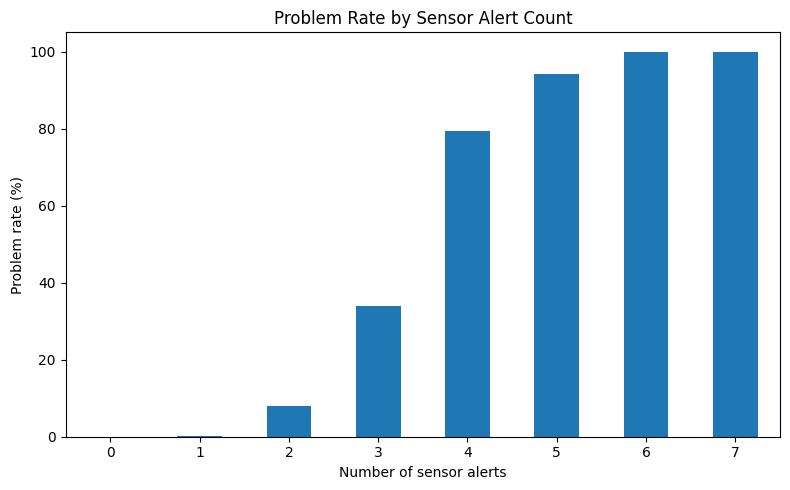

In [62]:
sensor_counts['prob_pct'].sort_index().plot(kind='bar', figsize=(8,5))
plt.xlabel('Number of sensor alerts')
plt.ylabel('Problem rate (%)')
plt.title('Problem Rate by Sensor Alert Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

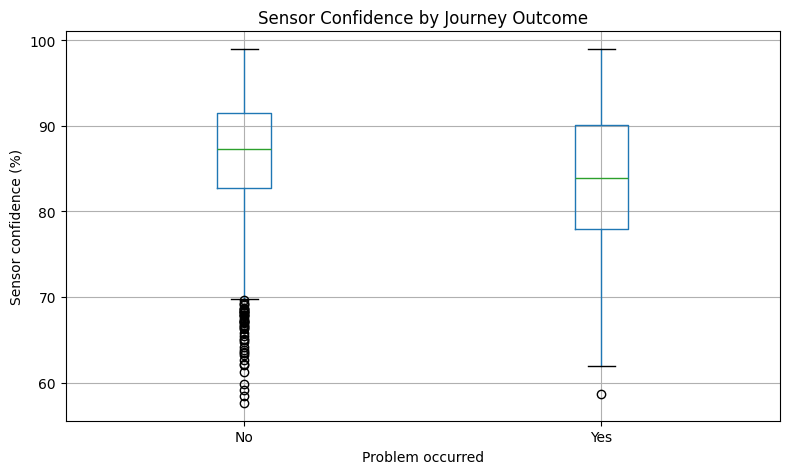

In [63]:
final_merged_table.boxplot(column='sensor_confidence_pct', by='problem_occurred', figsize=(8,5))
plt.suptitle('')
plt.title('Sensor Confidence by Journey Outcome')
plt.xlabel('Problem occurred')
plt.ylabel('Sensor confidence (%)')
plt.tight_layout()
plt.show()

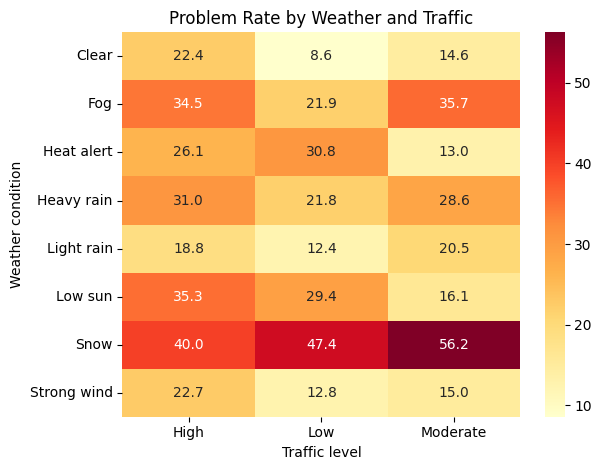

In [64]:
import seaborn as sns
weather_traffic = final_merged_table.pivot_table(index='weather', columns='traffic_level', values='problem_flag', aggfunc='mean') * 100

sns.heatmap(weather_traffic, annot=True, fmt='.1f', cmap='YlOrRd')
plt.xlabel('Traffic level')
plt.ylabel('Weather condition')
plt.title('Problem Rate by Weather and Traffic')
plt.tight_layout()
plt.show()

Investigating Humn intervention and emergency stops

What percentage of journeys required human intervention?

In [65]:
final_merged_table.head(20)

,journey_id,journey_date,time_of_day,city_x,road_segment_id,vehicle_profile_id,weather_code,road_type_x,distance_km,traffic_level,road_surface,visibility_km,planned_time_min,actual_time_min,delay_min,sensor_confidence_pct,sensor_alert_count,unexpected_obstacle,human_intervention,emergency_stop,safety_incident,journey_completed,passenger_rating_1to5,problem_occurred,risk_level,vehicle_model,software_version,sensor_suite,lidar_units,radar_units,camera_units,vehicle_age_months,nominal_sensor_confidence_pct,weather,risk_multiplier,visibility_factor,sensor_confidence_adjustment,city_y,road_type_y,speed_limit_mph,junction_complexity,road_markings,street_lighting,digital_infrastructure,event_id,event_type,event_reason,severity,response_action,outcome,problem_flag,confidence_group,visibility_group
0,AVJ-00001,2026-04-12,Morning peak,Newcastle,SEG-018,VP-08,W07,B road,39.2,High,Dry,9.6,71,78,7,87.6,2,No,No,No,No,Yes,4,No,Low,Vector One,5.0,Enhanced,3,7,10,10,90,Low sun,1.30,0.70,-6,Newcastle,B road,50,Low,Good,Standard,Standard,NaN,NaN,NaN,NaN,NaN,NaN,0,"(84.8, 88.6]","(0.249, 0.82]"
1,AVJ-00002,2026-06-01,Night,Cardiff,SEG-009,VP-04,W01,Urban street,49.0,Moderate,Dry,4.2,148,150,2,93.5,1,No,No,No,No,Yes,5,No,Low,Vector Plus,5.0,Enhanced,3,7,10,21,90,Clear,1.00,1.00,2,Cardiff,Urban street,30,High,Good,Good,Standard,NaN,NaN,NaN,NaN,NaN,NaN,0,"(92.1, 99.0]","(0.82, 1.0]"
2,AVJ-00003,2026-02-18,Daytime,Cardiff,SEG-027,VP-08,W05,A road,11.3,Moderate,Snow-covered,4.0,17,36,19,65.9,5,No,Yes,Yes,No,Yes,2,Yes,High,Vector One,5.0,Enhanced,3,7,10,10,90,Snow,1.85,0.45,-15,Cardiff,A road,60,Low,Good,Standard,Standard,EVT-0001,Emergency stop,Emergency stop,Medium,Safe stop and system check,Journey completed,1,"(57.599000000000004, 80.3]","(0.249, 0.82]"
3,AVJ-00004,2026-06-23,Daytime,Cardiff,SEG-021,VP-08,W02,Motorway,15.3,Moderate,Wet,10.3,20,21,1,82.0,2,No,No,No,No,Yes,4,No,Low,Vector One,5.0,Enhanced,3,7,10,10,90,Light rain,1.15,0.82,-3,Cardiff,Motorway,70,Medium,Good,Limited,Standard,NaN,NaN,NaN,NaN,NaN,NaN,0,"(80.3, 84.8]","(0.249, 0.82]"
4,AVJ-00005,2026-05-08,Daytime,Bristol,SEG-026,VP-04,W02,Motorway,25.1,Moderate,Wet,3.9,32,35,3,88.5,1,No,No,No,No,Yes,5,No,Low,Vector Plus,5.0,Enhanced,3,7,10,21,90,Light rain,1.15,0.82,-3,Bristol,Motorway,70,Low,Good,Standard,Standard,NaN,NaN,NaN,NaN,NaN,NaN,0,"(84.8, 88.6]","(0.249, 0.82]"
5,AVJ-00006,2026-04-14,Evening peak,Bristol,SEG-008,VP-01,W03,B road,26.0,High,Wet,1.2,47,55,8,72.5,4,No,No,No,No,Yes,4,No,Medium,Aurora A,4.1,Standard,2,5,8,6,86,Heavy rain,1.55,0.55,-10,Bristol,B road,50,Low,Poor,Standard,Standard,NaN,NaN,NaN,NaN,NaN,NaN,0,"(57.599000000000004, 80.3]","(0.249, 0.82]"
6,AVJ-00007,2026-02-16,Evening peak,Leeds,SEG-022,VP-08,W01,A road,7.6,High,Dry,4.8,11,31,20,82.7,3,No,Yes,No,No,Yes,2,Yes,Medium,Vector One,5.0,Enhanced,3,7,10,10,90,Clear,1.00,1.00,2,Leeds,A road,60,Low,Poor,Standard,Enhanced,EVT-0002,Human intervention,Complex traffic,Low,Manual control requested,Journey completed,1,"(80.3, 84.8]","(0.82, 1.0]"
7,AVJ-00008,2026-02-12,Night,Bristol,SEG-014,VP-05,W08,Urban street,15.0,High,Dry,4.6,45,56,11,91.3,2,No,Yes,No,Yes,No,2,Yes,High,Nexus City,4.1,Enhanced,3,7,10,26,90,Heat alert,1.12,0.95,-2,Bristol,Urban street,30,High,Good,Good,Standard,EVT-0003,Safety incident,Safety incident,High,Journey terminated,Journey not completed,1,"(88.6, 92.1]","(0.82, 1.0]"
8,AVJ-00009,2026-05-13,Evening peak,Bristol,SEG-014,VP-02,W01,Urban street,39.5,Moderate,Dry,18.4,119,121,2,83.4,2,No,No,No,No,Yes,5,No,Low,Aurora B,4.2,Standard,2,5,8,11,86,Clear,1.00,1.00,2,Bristol,Urban street,30,High,Good,Good,Standard,NaN,NaN,NaN,NaN,NaN,NaN,0,"(80.3, 84.8]","(0.82, 1.0]"
9,AVJ-00010,2026-05-19,Daytime,Manchester,SEG-011,VP-01,W01,Motorway,30.2,Low,Dry,12.8,39,40,1,85.5,2,No,No,No,No,Yes,5,No,Low,Aurora A,4.1,Standard,2,5,8,6,86,Clear,1.00,1.00,2,Manchester,Motorway,70,Low,Good,Standard,Standard,NaN,NaN,NaN,NaN,NaN,NaN,0,"(84.8, 88.6]","(0.82, 1.0]"


In [66]:
final_merged_table['human_intervention_journeys'] = (final_merged_table['human_intervention']== 'Yes').astype(int)

In [67]:
human_intervention_pct = final_merged_table['human_intervention_journeys'].mean() * 100
print(human_intervention_pct, '%')

13.8 %


In [68]:
total_journeys = len(final_merged_table)

required_journeys = final_merged_table['human_intervention_journeys'].sum()

no_required_journeys = (final_merged_table['human_intervention_journeys'] == 0).sum()

missing_outcomes = final_merged_table['human_intervention_journeys'].isna().sum()

print("Total journeys:", total_journeys)
print("Journeys with human intervention:", required_journeys)
print("Journeys without human intervention:", no_required_journeys)
print("Missing outcomes:", missing_outcomes)

Total journeys: 2500
Journeys with human intervention: 345
Journeys without human intervention: 2155
Missing outcomes: 0


In [69]:
print(final_merged_table['emergency_stop'].value_counts(dropna=False))

emergency_stop
No     2414
Yes      86
Name: count, dtype: int64


In [70]:
final_merged_table['emergency_stop_journeys'] = (final_merged_table['emergency_stop']== 'Yes').astype(int)

In [71]:
emergency_stop_pct = final_merged_table['emergency_stop_journeys'].mean() * 100
print(emergency_stop_pct, '%')

3.44 %


In [72]:
total_journeys = len(final_merged_table)
emergency_journeys = final_merged_table['emergency_stop_journeys'].sum()
no_emergency_journeys = (final_merged_table['emergency_stop_journeys'] == 0).sum()

emergency_stop_pct = final_merged_table['emergency_stop_journeys'].mean() * 100

print("Total journeys:", total_journeys)
print("Journeys with emergency stops:", emergency_journeys)
print("Journeys without emergency stops:", no_emergency_journeys)
print("Emergency stop rate:", round(emergency_stop_pct, 2), "%")

Total journeys: 2500
Journeys with emergency stops: 86
Journeys without emergency stops: 2414
Emergency stop rate: 3.44 %


What were the most common interuption reasons?

In [73]:
print(intervention_events['event_reason'].value_counts(dropna=False))

event_reason
Precautionary intervention    105
Emergency stop                 79
Complex traffic                72
Low sensor confidence          45
Unexpected obstacle            44
Safety incident                32
Name: count, dtype: int64


In [74]:
reasons = final_merged_table.groupby('event_reason')['human_intervention_journeys'].agg(['count', 'sum', 'mean'])
reasons['pct']=reasons['mean'] *100
print(reasons.sort_values('mean',ascending=False))

                            count  sum      mean         pct
event_reason                                                
Complex traffic                72   72  1.000000  100.000000
Low sensor confidence          45   45  1.000000  100.000000
Unexpected obstacle            44   44  1.000000  100.000000
Precautionary intervention    105  105  1.000000  100.000000
Emergency stop                 79   60  0.759494   75.949367
Safety incident                32   19  0.593750   59.375000


which weather or road conditions were associated with more interventions?

In [75]:
intervention_weather = final_merged_table.groupby('weather')['human_intervention_journeys'].agg(['count', 'sum', 'mean'])
intervention_weather['intervention_pct'] = intervention_weather['mean'] * 100
print(intervention_weather.sort_values('intervention_pct', ascending=False).round(2))

             count  sum  mean  intervention_pct
weather                                        
Snow            86   26  0.30             30.23
Fog            160   38  0.24             23.75
Heat alert      59   11  0.19             18.64
Heavy rain     203   37  0.18             18.23
Strong wind    163   24  0.15             14.72
Low sun        141   20  0.14             14.18
Light rain     475   60  0.13             12.63
Clear         1213  129  0.11             10.63


In [76]:
intervention_road = final_merged_table.groupby('road_surface')['human_intervention_journeys'].agg(['count', 'sum', 'mean'])
intervention_road['intervention_pct'] = intervention_road['mean'] * 100
print(intervention_road.sort_values('intervention_pct', ascending=False).round(2))

              count  sum  mean  intervention_pct
road_surface                                    
Snow-covered     86   26  0.30             30.23
Wet             678   97  0.14             14.31
Dry            1652  213  0.13             12.89
Uneven           84    9  0.11             10.71


Were certain intervention types associated with more severe outcomes?

In [77]:
print(intervention_events['event_type'].value_counts(dropna=False))
print(intervention_events['severity'].value_counts(dropna=False))
print(intervention_events['outcome'].value_counts(dropna=False))

event_type
Human intervention    266
Emergency stop         79
Safety incident        32
Name: count, dtype: int64
severity
Low       252
Medium     93
High       32
Name: count, dtype: int64
outcome
Journey completed        324
Journey not completed     53
Name: count, dtype: int64


In [78]:
event_severity = pd.crosstab(intervention_events['event_type'], intervention_events['severity'], margins=True)
print(event_severity)

severity            High  Low  Medium  All
event_type                                
Emergency stop         0    0      79   79
Human intervention     0  252      14  266
Safety incident       32    0       0   32
All                   32  252      93  377


Summary;

The exploratory analysis identified several factors associated with autonomous vehicle journey problems. Snow recorded the highest problem rate (47.67%), while snow-covered roads also had the highest intervention rate (30.23%). Lower sensor confidence was associated with higher problem rates, particularly in the lowest confidence group (31.21%). Repeated sensor alerts showed an increasing pattern, with journeys experiencing five alerts recording a 94.12% problem rate.

Human interventions were more frequent during snow and fog, while safety incidents were consistently classified as high severity in the recorded event data.

Overall, the findings suggest that environmental conditions and sensor reliability are important areas for further investigation. However, these associations do not establish causation, and the dataset is synthetic. Further analysis is needed to investigate combinations of factors and identify useful predictors before building a classification model.

Do difficult weather conditions combined with different traffic levels correspond with higher autonomous vehicle problem rates?

In [79]:
pivot = pd.pivot_table(final_merged_table, values='problem_flag', index='weather', columns='traffic_level', aggfunc='mean') * 100
print(pivot.round(1))

traffic_level  High   Low  Moderate
weather                            
Clear          22.4   8.6      14.6
Fog            34.5  21.9      35.7
Heat alert     26.1  30.8      13.0
Heavy rain     31.0  21.8      28.6
Light rain     18.8  12.4      20.5
Low sun        35.3  29.4      16.1
Snow           40.0  47.4      56.2
Strong wind    22.7  12.8      15.0


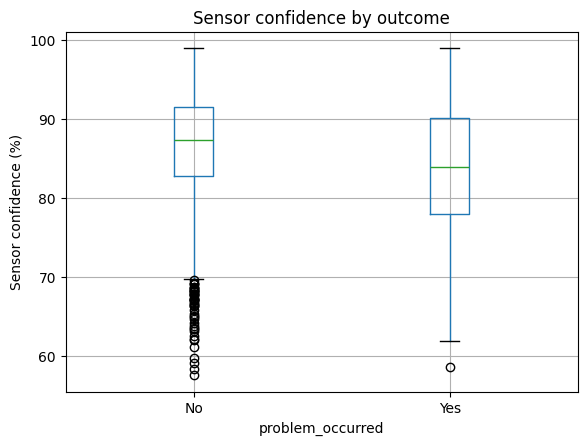

In [80]:
final_merged_table.boxplot(column='sensor_confidence_pct', by='problem_occurred')
plt.suptitle('')
plt.title('Sensor confidence by outcome')
plt.ylabel('Sensor confidence (%)')
plt.show()

Choose target variable

In [81]:
y = final_merged_table['problem_flag']

Select the predictor variables

In [82]:
features = ['time_of_day', 'road_type_x', 'traffic_level', 'road_surface', 'visibility_km', 'distance_km', 'sensor_confidence_pct', 'sensor_alert_count', 'unexpected_obstacle']

Convert categorical variables into numerical variables

In [83]:
X = pd.get_dummies(final_merged_table[features], drop_first=True)
y = final_merged_table['problem_flag']

In [84]:
print(X.head())
print(X.shape)
print(y.value_counts())

   visibility_km  distance_km  sensor_confidence_pct  sensor_alert_count  \
0            9.6         39.2                   87.6                   2   
1            4.2         49.0                   93.5                   1   
2            4.0         11.3                   65.9                   5   
3           10.3         15.3                   82.0                   2   
4            3.9         25.1                   88.5                   1   

   time_of_day_Evening peak  time_of_day_Late night  time_of_day_Morning peak  \
0                     False                   False                      True   
1                     False                   False                     False   
2                     False                   False                     False   
3                     False                   False                     False   
4                     False                   False                     False   

   time_of_day_Night  road_type_x_B road  road_type_x_Mo

In [85]:
print(X.isnull().sum())
print(y.isnull().sum())

visibility_km                0
distance_km                  0
sensor_confidence_pct        0
sensor_alert_count           0
time_of_day_Evening peak     0
time_of_day_Late night       0
time_of_day_Morning peak     0
time_of_day_Night            0
road_type_x_B road           0
road_type_x_Motorway         0
road_type_x_Rural road       0
road_type_x_Urban street     0
traffic_level_Low            0
traffic_level_Moderate       0
road_surface_Snow-covered    0
road_surface_Uneven          0
road_surface_Wet             0
unexpected_obstacle_Yes      0
dtype: int64
0


Build a transparent model

In [86]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [87]:
print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

Training predictors: (2000, 18)
Testing predictors: (500, 18)
Training target: (2000,)
Testing target: (500,)
problem_flag
0    1599
1     401
Name: count, dtype: int64
problem_flag
0    400
1    100
Name: count, dtype: int64


In [88]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, class_weight='balanced')

In [89]:
#train the model
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [90]:
y_pred = model.predict(X_test)

In [91]:
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(comparison.head(10))

      Actual  Predicted
1726       1          1
1321       0          0
1871       0          0
852        0          0
498        0          1
1796       1          1
759        0          0
1765       0          0
899        1          1
597        1          1


In [92]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))

Accuracy: 0.944
Precision: 0.7903225806451613
Recall: 0.98
F1-score: 0.875


In [93]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[374  26]
 [  2  98]]


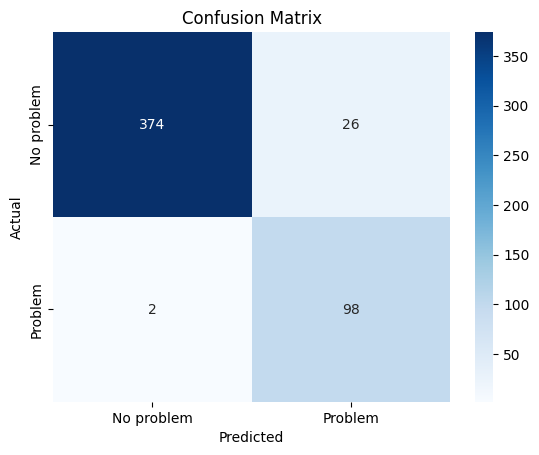

In [94]:
import seaborn as sns

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No problem', 'Problem'], yticklabels=['No problem', 'Problem'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Model 2

In [95]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')

In [96]:
tree.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=4, random_state=42)

In [97]:
tree_pred = tree.predict(X_test)

print("Accuracy:", accuracy_score(y_test, tree_pred))
print("Precision:", precision_score(y_test, tree_pred))
print("Recall:", recall_score(y_test, tree_pred))
print("F1-score:", f1_score(y_test, tree_pred))

Accuracy: 0.894
Precision: 0.6577181208053692
Recall: 0.98
F1-score: 0.7871485943775101


In [98]:
tree_cm = confusion_matrix(y_test, tree_pred)
print(tree_cm)

[[349  51]
 [  2  98]]


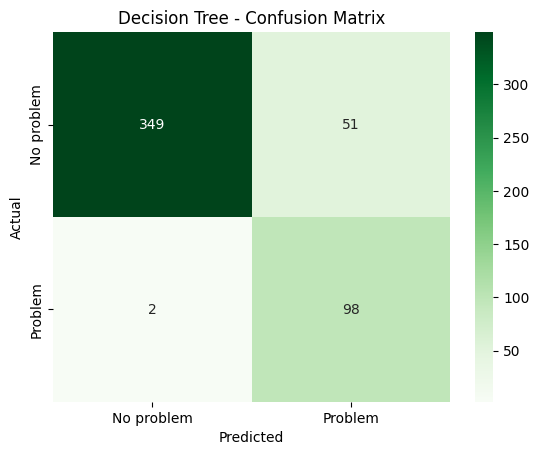

In [99]:
sns.heatmap(tree_cm, annot=True, fmt='d', cmap='Greens', xticklabels=['No problem', 'Problem'], yticklabels=['No problem', 'Problem'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree - Confusion Matrix')
plt.show()

In [100]:
importance = pd.Series(model.coef_[0], index=X.columns)
importance = importance.reindex(importance.abs().sort_values(ascending=False).index)
print(importance.head(12))

sensor_alert_count           5.645066
road_surface_Snow-covered    1.320258
traffic_level_Low           -0.951742
sensor_confidence_pct        0.573989
road_type_x_Motorway        -0.558664
time_of_day_Morning peak     0.303010
road_surface_Wet            -0.297144
road_type_x_B road          -0.280862
road_type_x_Rural road      -0.277040
time_of_day_Late night      -0.272287
time_of_day_Evening peak     0.191059
traffic_level_Moderate      -0.188019
dtype: float64


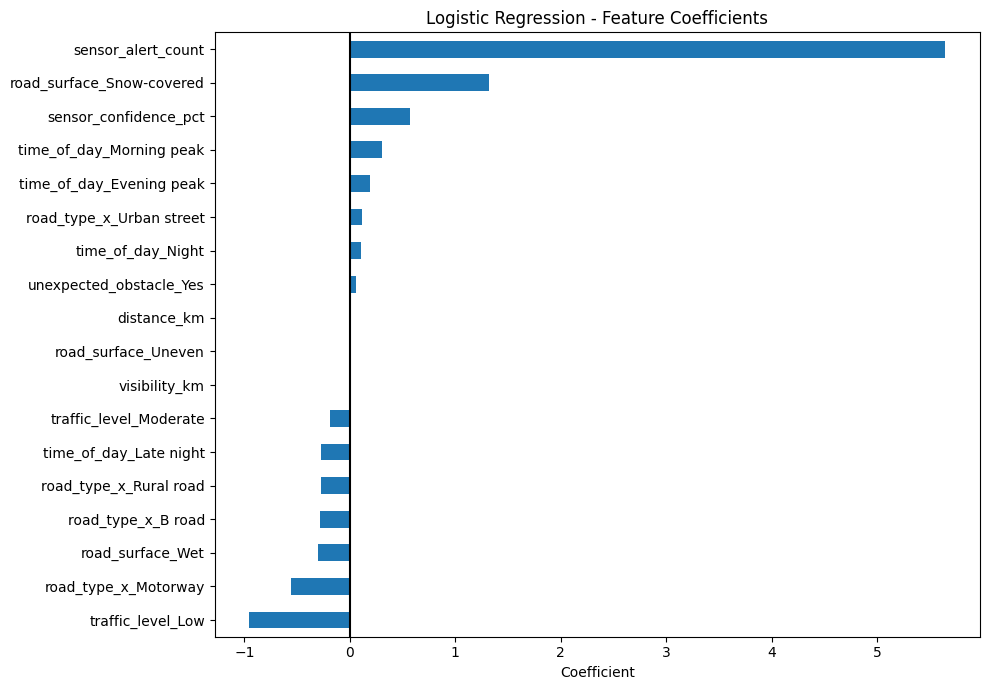

In [101]:
importance.sort_values().plot(kind='barh', figsize=(10, 7))
plt.axvline(x=0, color='black')
plt.xlabel('Coefficient')
plt.title('Logistic Regression - Feature Coefficients')
plt.tight_layout()
plt.show()

In [102]:
tree_importance = pd.Series(tree.feature_importances_, index=X.columns)
tree_importance = tree_importance.sort_values(ascending=False)
print(tree_importance.head(12))

sensor_alert_count          0.715386
sensor_confidence_pct       0.284360
unexpected_obstacle_Yes     0.000254
visibility_km               0.000000
distance_km                 0.000000
time_of_day_Evening peak    0.000000
time_of_day_Morning peak    0.000000
time_of_day_Night           0.000000
road_type_x_B road          0.000000
time_of_day_Late night      0.000000
road_type_x_Motorway        0.000000
road_type_x_Rural road      0.000000
dtype: float64


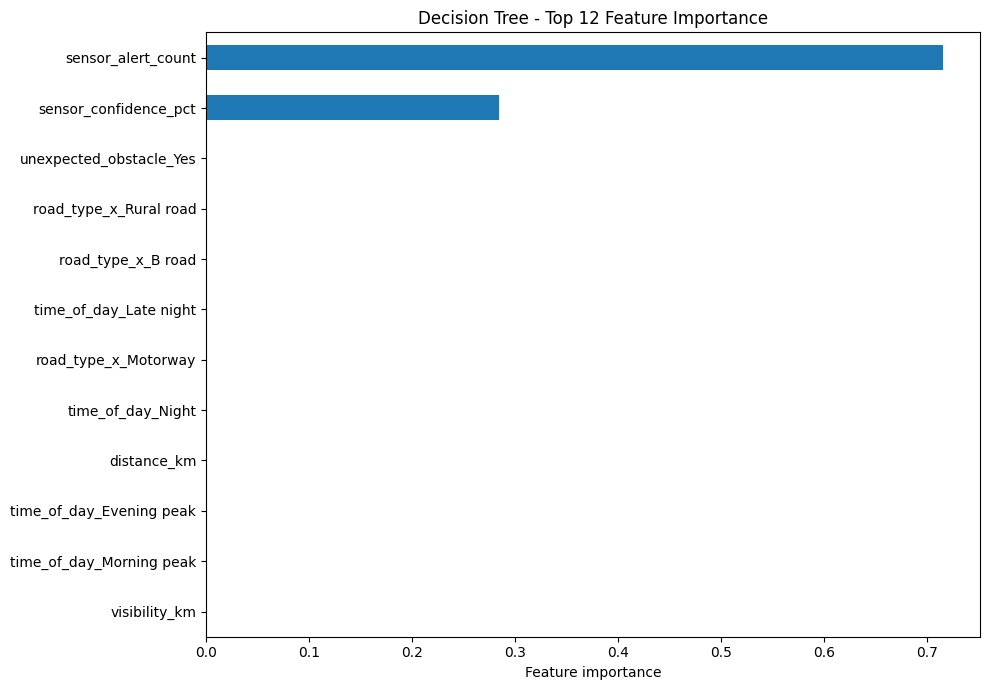

In [103]:
tree_importance.head(12).sort_values().plot(kind='barh', figsize=(10, 7))
plt.xlabel('Feature importance')
plt.title('Decision Tree - Top 12 Feature Importance')
plt.tight_layout()
plt.show()